# 07 Embedding MLP and temporal (GRU) model

Two neural models, both in PyTorch, both trained on Jan-Sep and tuned on Oct-Nov exactly like Phase 1:

* **Embedding MLP** (required by the project brief): carrier, origin and destination get learned embedding
  vectors, which are concatenated with the 32 numeric features and passed through two ReLU layers.
* **Temporal model**: the same MLP plus a small GRU that reads the 14 days of airport / carrier / system
  delay statistics before the flight date (built and leakage-tested in notebook 06).

Why these two. Phase 1 LR and XGBoost only see hand-made summaries of the past (7-day rate, yesterday's rate).
The gap named in the brief is that such summaries "may miss complex interactions between time, airport,
carrier and recent delay dynamics". Embeddings let similar airports/carriers share statistical strength;
the GRU sees the ordered trajectory, not just its mean.

Every choice (architecture, dropout, weight decay, learning rate, number of epochs) is made on
**validation PR-AUC**. December is only scored.

In [1]:
import copy
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score

plt.rcParams.update({"font.size": 7, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from pathlib import Path

ROOT = Path("..").resolve()
PROCESSED_DIR = ROOT / "data" / "processed"
MODEL_DIR = ROOT / "models"
RESULTS_DIR = ROOT / "results"
FIG_DIR = RESULTS_DIR / "figures"
for d in (MODEL_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
torch.set_num_threads(4)

In [3]:
data = np.load(PROCESSED_DIR / "dl_inputs.npz")
with open(PROCESSED_DIR / "dl_preprocessing.json") as f:
    prep = json.load(f)

DAILY = torch.tensor(data["daily"])
MAX_SEQ_LEN = prep["max_seq_len"]
CARDS = [len(prep["vocab"][c]) + 1 for c in prep["cat_cols"]]   # +1 for the unknown id 0


def load_split(s):
    return {"num": torch.tensor(data[f"{s}_num"]), "cat": torch.tensor(data[f"{s}_cat"]),
            "day": torch.tensor(data[f"{s}_day"]), "org": torch.tensor(data[f"{s}_seq_origin"]),
            "y": torch.tensor(data[f"{s}_y"])}


train, val, test = (load_split(s) for s in ("train", "val", "test"))
TRAIN_RATE = float(train["y"].mean())
{"train": len(train["y"]), "val": len(val["y"]), "test": len(test["y"]), "categories": CARDS}

{'train': 244737, 'val': 55589, 'test': 27020, 'categories': [17, 4, 104]}

## The network

For a flight with numeric features $x$, categories $(c, o, d)$ and history sequence $s_{1..L}$:

$$u = [\,x;\ E_c[c];\ E_o[o];\ E_d[d];\ h_L\,], \qquad h_t = \mathrm{GRU}(s_t, h_{t-1})$$
$$a_1 = \mathrm{Dropout}(\mathrm{ReLU}(W_1 u + b_1)),\quad a_2 = \mathrm{Dropout}(\mathrm{ReLU}(W_2 a_1 + b_2)),
\quad p = \sigma(w_3^\top a_2 + b_3)$$

* Embedding size: $\min(10,\ \mathrm{round}(1.6\,n^{0.56}))$ for $n$ categories (the fast.ai rule of thumb),
  so carrier 8, origin 3, destination 10. Row 0 (unknown) is a fixed zero vector (`padding_idx=0`).
* The GRU (hidden size 16 or 32) reads the sequence in time order and only its last state $h_L$ goes into
  the MLP. Without the GRU branch this is the plain embedding MLP.
* `cat_mode="onehot"` replaces the embeddings with one-hot vectors (used in the ablation notebook).
* The output bias starts at $\mathrm{logit}(\bar y_{train})$ so training starts from the base rate.

In [4]:
def emb_dim(n):
    return min(10, round(1.6 * n ** 0.56))


class DelayNet(nn.Module):
    def __init__(self, n_num, cards, hidden=(128, 64), dropout=0.2, seq_len=0, gru_hidden=16,
                 cat_mode="embedding", daily=None):
        super().__init__()
        self.cards, self.cat_mode, self.seq_len = cards, cat_mode, seq_len
        if cat_mode == "embedding":
            self.embs = nn.ModuleList(nn.Embedding(n, emb_dim(n), padding_idx=0) for n in cards)
            width = n_num + sum(emb_dim(n) for n in cards)
        else:
            width = n_num + sum(cards)
        if seq_len:
            self.register_buffer("daily", daily)
            self.gru = nn.GRU(daily.shape[-1], gru_hidden, batch_first=True)
            width += gru_hidden
        layers = []
        for h in hidden:
            layers += [nn.Linear(width, h), nn.ReLU(), nn.Dropout(dropout)]
            width = h
        layers.append(nn.Linear(width, 1))
        self.mlp = nn.Sequential(*layers)

    def history(self, cat, day, org):
        # days d-L .. d-1 of the flight's origin airport and carrier (the daily table is padded at the front)
        steps = day[:, None] + MAX_SEQ_LEN - self.seq_len + torch.arange(self.seq_len)
        return self.daily[org[:, None], cat[:, :1], steps]

    def forward(self, num, cat, day, org):
        parts = [num]
        if self.cat_mode == "embedding":
            parts += [emb(cat[:, i]) for i, emb in enumerate(self.embs)]
        else:
            parts += [F.one_hot(cat[:, i], n).float() for i, n in enumerate(self.cards)]
        if self.seq_len:
            _, h = self.gru(self.history(cat, day, org))
            parts.append(h[-1])
        return self.mlp(torch.cat(parts, dim=1)).squeeze(1)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## Training loop

* Loss: binary cross-entropy on the logit (`binary_cross_entropy_with_logits`, numerically stable).
  No class weights: Phase 1 showed weighting does not change ranking but ruins calibration.
* Optimiser: AdamW (decoupled weight decay) on weights and embeddings; biases are not decayed.
* Gradient norm clipped at 5 (cheap protection for the GRU).
* Early stopping: after every epoch we score validation PR-AUC; training stops after 4 epochs without
  improvement and the best epoch's weights are restored.

In [5]:
def batch_inputs(t, idx=slice(None)):
    return t["num"][idx], t["cat"][idx], t["day"][idx], t["org"][idx]


def predict(model, t, batch_size=8192):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(t["y"]), batch_size):
            out.append(torch.sigmoid(model(*batch_inputs(t, slice(i, i + batch_size)))))
    return torch.cat(out).numpy()


def make_model(cfg):
    return DelayNet(train["num"].shape[1], CARDS, hidden=cfg["hidden"], dropout=cfg["dropout"],
                    seq_len=cfg.get("seq_len", 0), gru_hidden=cfg.get("gru_hidden", 16),
                    cat_mode=cfg.get("cat_mode", "embedding"), daily=DAILY)


def train_model(cfg, seed=SEED, max_epochs=40, patience=4, batch_size=1024, early_stopping=True,
                data_train=None, data_val=None, build=make_model):
    data_train = data_train or train
    data_val = data_val or val
    torch.manual_seed(seed)
    model = build(cfg)
    with torch.no_grad():
        model.mlp[-1].bias.fill_(np.log(TRAIN_RATE / (1 - TRAIN_RATE)))
    decay = [p for n, p in model.named_parameters() if p.ndim > 1]
    no_decay = [p for n, p in model.named_parameters() if p.ndim <= 1]
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": cfg["weight_decay"]},
                             {"params": no_decay, "weight_decay": 0.0}], lr=cfg["lr"])
    gen = torch.Generator().manual_seed(seed)
    y_val = data_val["y"].numpy()
    best_ap, best_state, best_epoch, bad, history = -1, None, 0, 0, []
    start = time.time()
    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(len(data_train["y"]), generator=gen)
        total = 0.0
        for i in range(0, len(perm), batch_size):
            idx = perm[i:i + batch_size]
            loss = F.binary_cross_entropy_with_logits(model(*batch_inputs(data_train, idx)), data_train["y"][idx])
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            total += loss.item() * len(idx)
        p_val = predict(model, data_val)
        ap = average_precision_score(y_val, p_val)
        history.append({"epoch": epoch, "train_loss": total / len(perm),
                        "val_loss": log_loss(y_val, p_val), "val_pr_auc": ap})
        if ap > best_ap:
            best_ap, best_state, best_epoch, bad = ap, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            bad += 1
            if early_stopping and bad >= patience:
                break
    if early_stopping:
        model.load_state_dict(best_state)
    else:
        best_epoch = epoch
    model.eval()
    info = {"best_epoch": best_epoch, "epochs_run": epoch, "val_pr_auc": average_precision_score(y_val, predict(model, data_val)),
            "seconds": round(time.time() - start, 1), "params": count_params(model)}
    return model, pd.DataFrame(history), info

## Sanity check: can the network learn at all?

A standard debugging step: on 256 training flights with dropout and weight decay switched off, a correct
network and training loop must be able to drive the training loss close to zero (memorise them).

In [6]:
torch.manual_seed(0)
tiny_idx = torch.arange(256)
tiny = {k: v[tiny_idx] for k, v in train.items()}
net = make_model({"hidden": (128, 64), "dropout": 0.0, "seq_len": 14, "gru_hidden": 16})
opt = torch.optim.Adam(net.parameters(), lr=3e-3)
for step in range(600):
    loss = F.binary_cross_entropy_with_logits(net(*batch_inputs(tiny)), tiny["y"])
    opt.zero_grad()
    loss.backward()
    opt.step()
    if step in (0, 100, 300, 599):
        print(f"step {step:3d}  training loss {loss.item():.4f}")
assert loss.item() < 0.05

step   0  training loss 0.7392
step 100  training loss 0.0088


step 300  training loss 0.0005


step 599  training loss 0.0001


## Hyperparameter search (validation PR-AUC)

Small grid, same for both models: two network sizes, two dropout rates, two weight-decay strengths, two
learning rates. The temporal model additionally tries a GRU of 16 or 32 units. One seed (42) per setting.

In [7]:
GRID = [{"hidden": h, "dropout": dr, "weight_decay": wd, "lr": lr}
        for h in [(64, 32), (128, 64)] for dr in (0.1, 0.3) for wd in (1e-4, 1e-2) for lr in (1e-3, 3e-4)]
SEARCH = [("MLP", {**g, "seq_len": 0}) for g in GRID]
SEARCH += [("Temporal", {**g, "seq_len": 14, "gru_hidden": gh}) for g in GRID for gh in (16, 32)]

rows = []
for kind, cfg in SEARCH:
    _, _, info = train_model(cfg)
    rows.append({"model": kind, **cfg, **info})
tuning = pd.DataFrame(rows)
tuning["hidden"] = tuning["hidden"].astype(str)
tuning.to_csv(RESULTS_DIR / "dl_tuning.csv", index=False)
tuning.sort_values("val_pr_auc", ascending=False).groupby("model").head(5).round(4)

,model,hidden,dropout,weight_decay,lr,seq_len,best_epoch,epochs_run,val_pr_auc,seconds,params,gru_hidden
24,Temporal,"(64, 32)",0.3,0.0001,0.0010,14,4,8,0.2980,9.3,9125,16.0
28,Temporal,"(64, 32)",0.3,0.0100,0.0010,14,4,8,0.2979,9.0,9125,16.0
16,Temporal,"(64, 32)",0.1,0.0001,0.0010,14,4,8,0.2960,8.8,9125,16.0
20,Temporal,"(64, 32)",0.1,0.0100,0.0010,14,3,7,0.2958,7.8,9125,16.0
30,Temporal,"(64, 32)",0.3,0.0100,0.0003,14,10,14,0.2956,15.6,9125,16.0
4,MLP,"(64, 32)",0.3,0.0001,0.0010,0,5,9,0.2931,2.1,6757,NaN
6,MLP,"(64, 32)",0.3,0.0100,0.0010,0,5,9,0.2930,2.1,6757,NaN
1,MLP,"(64, 32)",0.1,0.0001,0.0003,0,8,12,0.2928,2.8,6757,NaN
3,MLP,"(64, 32)",0.1,0.0100,0.0003,0,8,12,0.2927,2.8,6757,NaN
5,MLP,"(64, 32)",0.3,0.0001,0.0003,0,11,15,0.2918,3.4,6757,NaN


In [8]:
best_cfg = {}
for kind in ("MLP", "Temporal"):
    i = tuning[tuning["model"] == kind]["val_pr_auc"].idxmax()
    best_cfg[kind] = SEARCH[i][1]
    print(kind, best_cfg[kind], f"val PR-AUC {tuning.loc[i, 'val_pr_auc']:.4f}")

MLP {'hidden': (64, 32), 'dropout': 0.3, 'weight_decay': 0.0001, 'lr': 0.001, 'seq_len': 0} val PR-AUC 0.2931
Temporal {'hidden': (64, 32), 'dropout': 0.3, 'weight_decay': 0.0001, 'lr': 0.001, 'seq_len': 14, 'gru_hidden': 16} val PR-AUC 0.2980


How sensitive is the result to the hyperparameters? The spread of validation PR-AUC over the grid:

In [9]:
tuning.groupby("model")["val_pr_auc"].describe()[["min", "50%", "max"]].round(4)

,min,50%,max
model,,,
MLP,0.2889,0.2906,0.2931
Temporal,0.2890,0.2936,0.2980


## Final models: three seeds each

A neural network's result depends on its random initialisation and batch order. We retrain the selected
setting with seeds 42, 43, 44. Seed 42 is the model used from here on (it was fixed before looking at
any test number); the other two only measure the spread.

In [10]:
SEEDS = (42, 43, 44)
final, curves, seed_rows = {}, [], []
y_val, y_test = val["y"].numpy(), test["y"].numpy()
pred_val, pred_test = {}, {}

for kind in ("MLP", "Temporal"):
    for seed in SEEDS:
        model, hist, info = train_model(best_cfg[kind], seed=seed)
        pv, pt = predict(model, val), predict(model, test)
        col = f"p_{kind.lower()}" + ("" if seed == SEED else f"_s{seed}")
        pred_val[col], pred_test[col] = pv, pt
        seed_rows.append({"model": kind, "seed": seed, **info,
                          "test_pr_auc": average_precision_score(y_test, pt),
                          "test_roc_auc": roc_auc_score(y_test, pt)})
        curves.append(hist.assign(model=kind, seed=seed))
        if seed == SEED:
            final[kind] = model

seeds = pd.DataFrame(seed_rows)
seeds.to_csv(RESULTS_DIR / "dl_seed_runs.csv", index=False)
pd.concat(curves).to_csv(RESULTS_DIR / "dl_learning_curves.csv", index=False)
seeds.round(4)

,model,seed,best_epoch,epochs_run,val_pr_auc,seconds,params,test_pr_auc,test_roc_auc
0,MLP,42,5,9,0.2931,2.1,6757,0.4973,0.6611
1,MLP,43,5,9,0.2921,2.1,6757,0.4977,0.6614
2,MLP,44,4,8,0.2891,1.9,6757,0.4958,0.6595
3,Temporal,42,4,8,0.2980,9.1,9125,0.5030,0.6702
4,Temporal,43,1,5,0.2905,5.6,9125,0.4881,0.6546
5,Temporal,44,3,7,0.2923,7.9,9125,0.5068,0.6706


In [11]:
seeds.groupby("model")[["val_pr_auc", "test_pr_auc", "test_roc_auc"]].agg(["mean", "std"]).round(4)

val_pr_auc         test_pr_auc         test_roc_auc        
               mean     std        mean     std         mean     std
model                                                               
MLP          0.2914  0.0021      0.4969  0.0010       0.6607  0.0010
Temporal     0.2936  0.0039      0.4993  0.0099       0.6652  0.0091

## Learning curves (seed 42)

Training loss keeps falling while validation loss turns up after a few epochs: the networks start to
overfit the training months quickly. Early stopping keeps the epoch with the best validation PR-AUC
(marked with a dot).

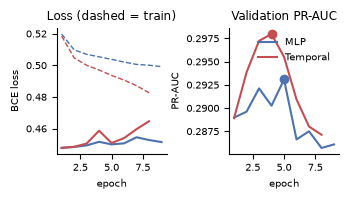

In [12]:
lc = pd.concat(curves)
fig, axes = plt.subplots(1, 2, figsize=(3.5, 2.0), sharex=True)
for kind, color in (("MLP", "#4C72B0"), ("Temporal", "#C44E52")):
    h = lc[(lc["model"] == kind) & (lc["seed"] == SEED)]
    best = h.loc[h["val_pr_auc"].idxmax()]
    axes[0].plot(h["epoch"], h["train_loss"], color=color, ls="--", lw=1)
    axes[0].plot(h["epoch"], h["val_loss"], color=color, label=kind)
    axes[1].plot(h["epoch"], h["val_pr_auc"], color=color, label=kind)
    axes[1].plot(best["epoch"], best["val_pr_auc"], "o", color=color)
axes[0].set(xlabel="epoch", ylabel="BCE loss", title="Loss (dashed = train)")
axes[1].set(xlabel="epoch", ylabel="PR-AUC", title="Validation PR-AUC")
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "learning_curves.pdf")
plt.show()

## Save models and predictions, and check that a reloaded model gives identical scores

In [13]:
for kind, model in final.items():
    torch.save({"config": best_cfg[kind], "state_dict": model.state_dict()}, MODEL_DIR / f"{kind.lower()}.pt")

for kind in final:
    ckpt = torch.load(MODEL_DIR / f"{kind.lower()}.pt")
    reloaded = make_model(ckpt["config"])
    reloaded.load_state_dict(ckpt["state_dict"])
    assert np.array_equal(predict(reloaded, test), pred_test[f"p_{kind.lower()}"])
print("reloaded models reproduce the saved predictions exactly")

ids = {s: data[f"{s}_id"] for s in ("val", "test")}
for s, preds in (("val", pred_val), ("test", pred_test)):
    pd.DataFrame({"id": ids[s], **preds}).to_pickle(PROCESSED_DIR / f"dl_predictions_{s}.pkl")

with open(RESULTS_DIR / "dl_selected.json", "w") as f:
    json.dump({k: {**v, "hidden": list(v["hidden"]),
                   "params": count_params(final[k]),
                   "best_epoch": int(seeds[(seeds.model == k) & (seeds.seed == SEED)]["best_epoch"].iloc[0])}
               for k, v in best_cfg.items()}, f, indent=2)
best_cfg

reloaded models reproduce the saved predictions exactly


{'MLP': {'hidden': (64, 32),
  'dropout': 0.3,
  'weight_decay': 0.0001,
  'lr': 0.001,
  'seq_len': 0},
 'Temporal': {'hidden': (64, 32),
  'dropout': 0.3,
  'weight_decay': 0.0001,
  'lr': 0.001,
  'seq_len': 14,
  'gru_hidden': 16}}